# Oversampling

### <i> Using GMM (Gaussian Mixture Model) </i> 

<i>

Gaussian Mixture Model looks at the entire dataframe from a probabilistic-lens. It uses the distributions for each columns, checks its variance, mean, and other statistics -- And combines them in the hopes of creating rows that are both realistic and add more information at the same time.


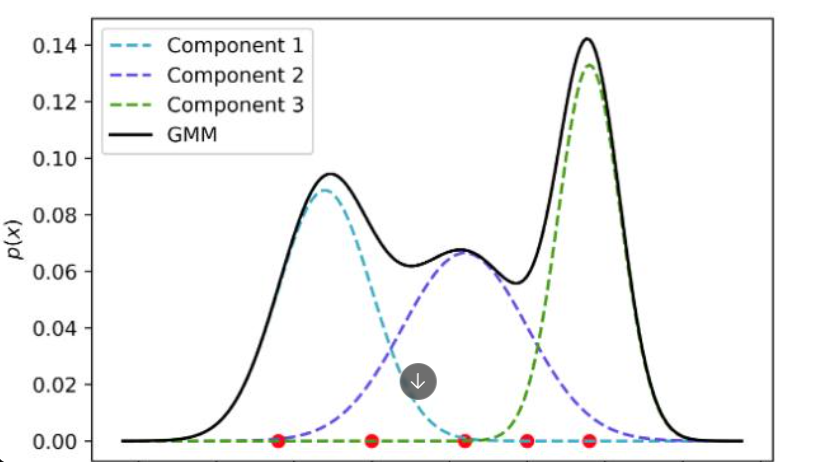

In [ ]:
# Let's open up the diamonds.csv dataset again.

# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Loading the dataset
df = pd.read_csv(
    "../diabetes.csv",
    index_col=0
)

# Binary encoding the `diabetes` column
variables = ['diabetes']
df[variables] = df[variables].replace({
    'neg': 0,
    'pos': 1
})

df

C:\Users\kykis\AppData\Local\Temp\ipykernel_32268\795410012.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[variables] = df[variables].replace({


,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
pregnant,,,,,,,,
1,89,66,23,94,28.1,0.167,21,0
0,137,40,35,168,43.1,2.288,33,1
3,78,50,32,88,31.0,0.248,26,1
2,197,70,45,543,30.5,0.158,53,1
1,189,60,23,846,30.1,0.398,59,1
...,...,...,...,...,...,...,...,...
0,181,88,44,510,43.3,0.222,26,1
1,128,88,39,110,36.5,1.057,37,1
2,88,58,26,16,28.4,0.766,22,0


---

### Example 1

<i> Synthesizing 500 rows.

In [2]:
# pip install scikit-learn
import pandas as pd
from sklearn.mixture import GaussianMixture

# Fit GMM to the original features
gmm = GaussianMixture(
    n_components=5,
    covariance_type="full",
    random_state=42
)

gmm.fit(df)

# Generate 500 synthetic rows
synthetic_data, component_labels = gmm.sample(500)

# Convert to a DataFrame
synthetic_df = pd.DataFrame(
    synthetic_data,
    columns=df.columns
)

synthetic_df

,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,163.443584,71.333158,16.213374,160.739412,31.588019,0.943560,33.896736,1.000950
1,113.986063,63.647636,24.445493,199.505128,36.041647,1.516708,37.554039,1.000598
2,104.561450,43.669728,30.764656,132.792870,22.516252,1.719962,30.250083,0.999364
3,176.218887,85.712643,21.991471,204.730629,37.698611,0.661374,43.924135,1.001092
4,114.402091,32.704587,30.080105,113.547678,28.398687,2.297867,37.624622,0.999462
...,...,...,...,...,...,...,...,...
495,106.704855,75.707677,50.208070,293.074112,48.586206,0.641917,26.583211,1.000820
496,148.902258,73.633819,36.884220,55.784008,38.102763,0.597054,34.024094,0.999730
497,100.162886,100.741458,35.545229,215.856577,46.692146,0.272102,46.198018,0.999873
498,169.174869,92.588307,37.696683,279.856085,40.873880,0.794740,45.638737,0.999787


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

Everything is converted to a float because it calculates the value of each column in a row based on probabilities. Here's how you fix that below...

</div>

---

### Example 2

<i> Synthesizing 500 rows while preserving integer datatypes.

In [3]:
# pip install scikit-learn
import pandas as pd
from sklearn.mixture import GaussianMixture

# Now we remember the datatypes 
original_dtypes = df.dtypes

# Fit GMM to the original features
gmm = GaussianMixture(
    n_components=5,
    covariance_type="full",
    random_state=42
)

gmm.fit(df)

# Generate 500 synthetic rows
synthetic_data, component_labels = gmm.sample(500)

# Convert to a DataFrame
synthetic_df = pd.DataFrame(
    synthetic_data,
    columns=df.columns
)

# Restore integer columns
for column in df.columns:
    # If the pandas dataframe datatype is an integer...
    if pd.api.types.is_integer_dtype(original_dtypes[column]):
        # Round it.
        synthetic_df[column] = synthetic_df[column].round().astype(
            original_dtypes[column]
        )

synthetic_df

,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,163,71,16,161,31.588019,0.943560,34,1
1,114,64,24,200,36.041647,1.516708,38,1
2,105,44,31,133,22.516252,1.719962,30,1
3,176,86,22,205,37.698611,0.661374,44,1
4,114,33,30,114,28.398687,2.297867,38,1
...,...,...,...,...,...,...,...,...
495,107,76,50,293,48.586206,0.641917,27,1
496,149,74,37,56,38.102763,0.597054,34,1
497,100,101,36,216,46.692146,0.272102,46,1
498,169,93,38,280,40.873880,0.794740,46,1


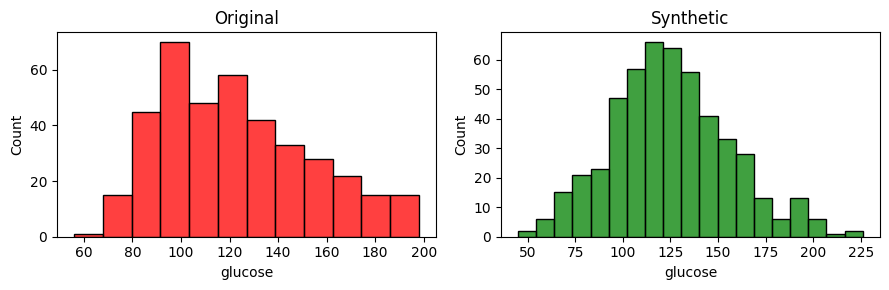

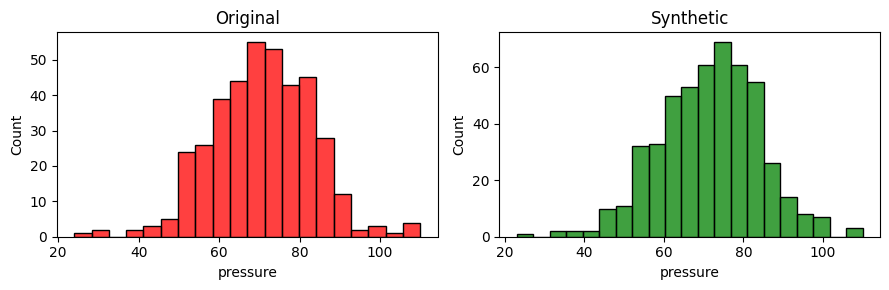

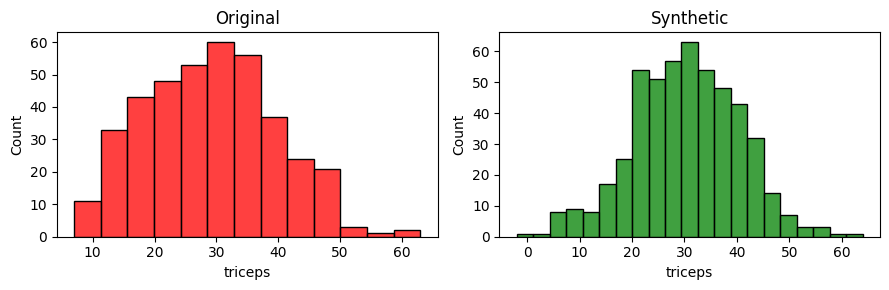

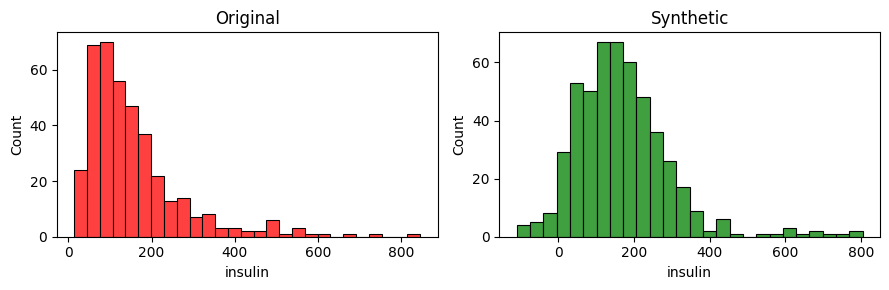

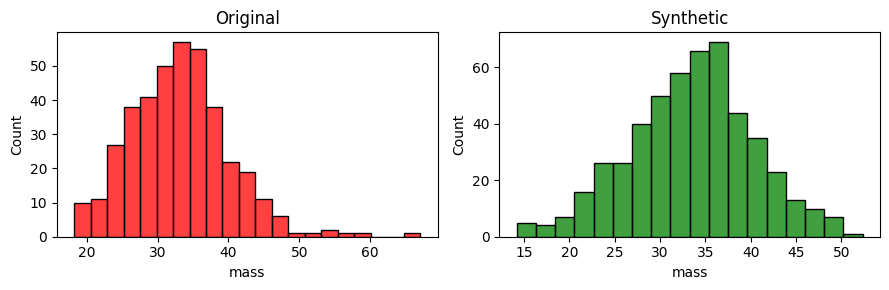

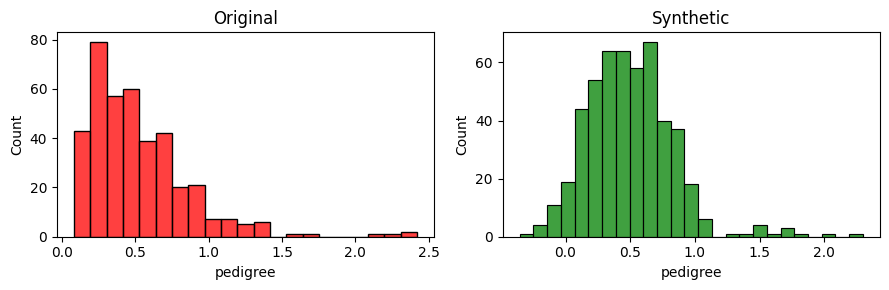

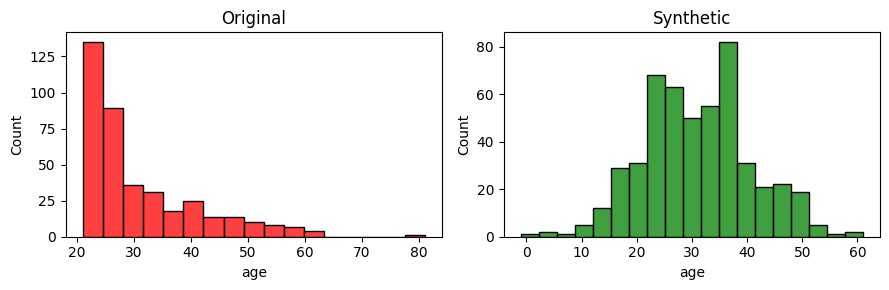

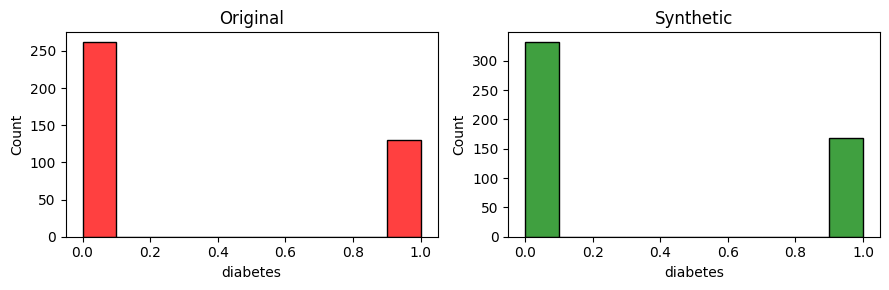

In [4]:

# Now we visualize the result. Are we happy with the result?
columns = synthetic_df.columns

for column in columns:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))

    sns.histplot(df, x=column,ax=axes[0], color="red")
    sns.histplot(synthetic_df, x=column,ax=axes[1], color="green")

    axes[0].set_title("Original")
    axes[1].set_title("Synthetic")

    # Prevents overlap between graphs
    plt.tight_layout()

    # Shows the plots
    plt.show()

# It's... not quite perfect, but it's undeniably fitting reasonably well!

In [5]:
df.describe()

,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,122.627551,70.663265,29.145408,156.056122,33.086224,0.523046,30.864796,0.331633
std,30.860781,12.496092,10.516424,118.841690,7.027659,0.345488,10.200777,0.471401
min,56.000000,24.000000,7.000000,14.000000,18.200000,0.085000,21.000000,0.000000
25%,99.000000,62.000000,21.000000,76.750000,28.400000,0.269750,23.000000,0.000000
50%,119.000000,70.000000,29.000000,125.500000,33.200000,0.449500,27.000000,0.000000
75%,143.000000,78.000000,37.000000,190.000000,37.100000,0.687000,36.000000,1.000000
max,198.000000,110.000000,63.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
synthetic_df.describe()

,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,125.020000,71.382000,30.174000,169.004000,33.471739,0.500667,31.012000,0.336000
std,30.913539,12.645786,10.086784,128.332047,6.824453,0.337690,9.604183,0.472812
min,45.000000,23.000000,-2.000000,-110.000000,14.187508,-0.353863,-1.000000,0.000000
25%,105.000000,63.000000,24.000000,85.750000,29.158788,0.259520,24.000000,0.000000
50%,123.000000,72.000000,30.000000,154.500000,33.925245,0.476544,31.000000,0.000000
75%,144.250000,80.000000,37.000000,226.000000,37.711449,0.683782,37.000000,1.000000
max,226.000000,110.000000,64.000000,805.000000,52.344103,2.297867,61.000000,1.000000


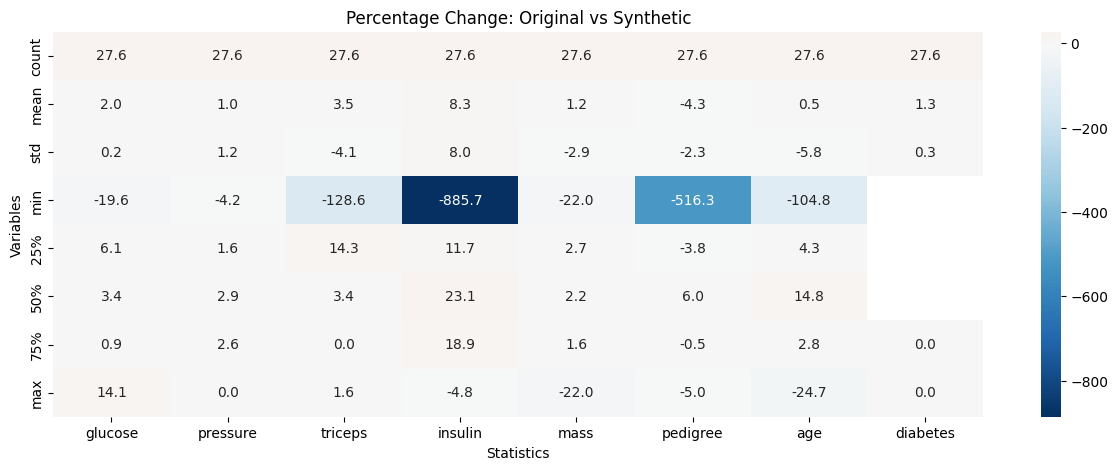

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Descriptive statistics
original = df.describe()
synthetic= synthetic_df.describe()

# Percentage difference
pct_change = ((synthetic - original) / original.abs()) * 100

plt.figure(figsize=(15, 5))
sns.heatmap(
    pct_change,
    annot=True,
    fmt=".1f",
    center=0,
    cmap="RdBu_r"
)

plt.title("Percentage Change: Original vs Synthetic")
plt.xlabel("Statistics")
plt.ylabel("Variables")
plt.show()

# The minimum values here might not reflect realism here -- So we might want to get
# rid of some of the smallest rows before concatenating the synthetic rows to our original 
# dataset!

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Key takeaways</h3>

* GMM is really good for when you need to keep the distributions as intact as possible. This could be because you maybe don't have a ton of rows to work with or that the performance of the real-life product is susceptible to distribution problems. 

* GMM is not worth considering when the distributions of your data don't reflect reality yet. In that case, GMM might make things worse (as it will reinforce that BAD distribution)

</div>